In [22]:
import pandas as pd
import os
import numpy as np
from nibabel.testing import data_path

data = pd.read_csv("./dataset/meta.csv", sep=";")
data
# data.value_counts("study_type")


,image_id,age,gender,institute,study_type,split,manufacturer,scanner_model,kvp,pathology,pathology_location
0,s1366,51,NaN,E,ct polytrauma,train,siemens,sensation 64,120,unclear,unclear
1,s0310,23,f,E,ct thorax-neck,train,siemens,somatom definition flash,100,no_pathology,no_location
2,s0250,68,m,E,ct neck-thorax-abdomen-pelvis,train,siemens,somatom definition flash,100,no_pathology,no_location
3,s0223,67,f,E,ct thorax-neck,train,siemens,sensation 64,120,no_pathology,no_location
4,s0011,45,m,B,ct neck-thorax-abdomen-pelvis,train,siemens,emotion 16,130,tumor,"thorax,abdomen,pelvis"
...,...,...,...,...,...,...,...,...,...,...,...
97,s0811,29,m,E,ct thorax,train,siemens,somatom definition edge,120,no_pathology,no_location
98,s1379,66,m,E,ct angiography thorax-abdomen-pelvis,train,siemens,somatom definition flash,100,vascular,abdomen
99,s0777,75,m,E,ct polytrauma,train,siemens,somatom force,130,no_pathology,no_location
100,s0763,56,m,E,ct polytrauma,train,siemens,somatom force,110,trauma,thorax



Image shape: (311, 311, 431)

Image orientation: R A S

 Data type of image:  int16

Voxel spacing:
 [[1.5 0.  0. ]
 [0.  1.5 0. ]
 [0.  0.  1.5]]

Voxel size:
 (np.float32(1.5), np.float32(1.5), np.float32(1.5))

Image origin:
 [-236.54492188  -45.54492188  -61.        ]

starting_physical_point: [-236.54492188  -45.54492188  -61.        ]

ending_physical_point: [529.95507812 720.95507812  95.        ]

Intensity data: [[[-1024. -1024. -1024. ... -1024. -1024. -1024.]
  [-1024. -1024. -1024. ... -1024. -1024. -1024.]
  [-1024. -1024. -1024. ... -1024. -1024. -1024.]
  ...
  [-1024. -1024. -1024. ... -1024. -1024. -1024.]
  [-1024. -1024. -1024. ... -1024. -1024. -1024.]
  [-1023. -1024. -1024. ... -1023. -1024. -1024.]]

 [[-1024. -1024. -1024. ... -1024. -1024. -1024.]
  [-1024. -1024. -1024. ... -1024. -1024. -1024.]
  [-1024. -1024. -1024. ... -1024. -1024. -1024.]
  ...
  [-1024. -1024. -1024. ... -1024. -1024. -1024.]
  [-1024. -1024. -1024. ... -1024. -1024. -1024.]
  [-1024. 

(array([6.0000000e+00, 5.0000000e+00, 1.4000000e+01, 3.2000000e+01,
        7.2000000e+01, 7.3000000e+01, 4.6200000e+02, 7.2500000e+02,
        1.5000000e+03, 2.4872500e+05, 1.9935204e+07, 3.6782580e+06,
        1.7210140e+06, 8.3023500e+05, 3.4135700e+05, 2.2457900e+05,
        1.7838100e+05, 1.4616000e+05, 1.3331100e+05, 1.1930600e+05,
        1.0824000e+05, 1.0140200e+05, 8.6747000e+04, 7.7744000e+04,
        8.4004000e+04, 1.0817700e+05, 4.6476800e+05, 4.2394390e+06,
        1.5385240e+06, 1.8520640e+06, 3.1378040e+06, 9.9894700e+05,
        4.0762600e+05, 2.4181300e+05, 1.7589000e+05, 1.3054800e+05,
        1.0093400e+05, 5.8151000e+04, 3.9307000e+04, 2.7881000e+04,
        2.1955000e+04, 1.7144000e+04, 1.3573000e+04, 1.1068000e+04,
        8.8290000e+03, 7.1310000e+03, 5.9610000e+03, 4.7300000e+03,
        4.1130000e+03, 3.4100000e+03, 2.8270000e+03, 2.0910000e+03,
        1.3220000e+03, 8.8000000e+02, 5.5800000e+02, 3.4700000e+02,
        2.5200000e+02, 1.6600000e+02, 1.6500000e

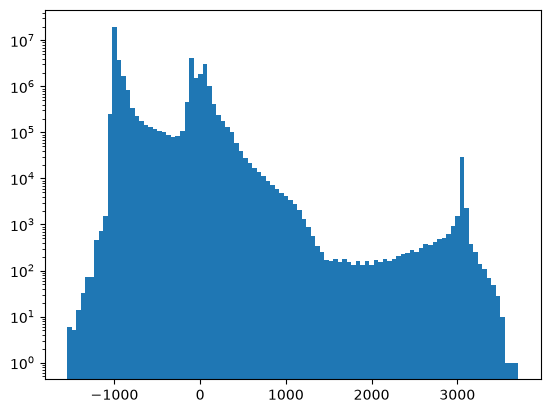

In [23]:
import nibabel as nib
import matplotlib.pyplot as plt
img = nib.load("./dataset/s0011/ct.nii.gz")
print('\nImage shape:', img.shape)

# check orientation of the 3D CT
x, y, z = nib.aff2axcodes(img.affine)
print('\nImage orientation:', x, y, z)

print("\n Data type of image: ", img.get_data_dtype())
voxel_spacing = img.affine[:3, :3]
image_origin = img.affine[:3, 3]

print('\nVoxel spacing:\n', voxel_spacing)
print('\nVoxel size:\n', img.header.get_zooms())

print('\nImage origin:\n', image_origin)

starting_physical_point = voxel_spacing.dot([0, 0, 0]) + image_origin
print('\nstarting_physical_point:', starting_physical_point)

ending_physical_point = voxel_spacing.dot([511, 511, 104]) + image_origin
print('\nending_physical_point:', ending_physical_point)

intensity = img.get_fdata(dtype=np.float32)
print('\nIntensity data:', intensity)
print("\nmax value: ", intensity.max())
print("\nmin value: ", intensity.min())
plt.hist(intensity.ravel(), bins=100, log=True)


